# 8. Optimización computacional

Con 140 combinaciones × 5 pliegues externos × 16 configuraciones × 3 pliegues internos, el
proyecto hace unos 34.000 ajustes. Este capítulo mide el costo de cada modelo, lo contrasta con su
complejidad teórica y muestra las optimizaciones que hicieron viable la corrida.

Todos los tiempos son de reloj (`time.perf_counter`), promediados en 2 o 3 repeticiones cuando el
costo lo permite, en un portátil con 12 hilos lógicos y una GPU NVIDIA RTX 3050 (6 GB). La memoria
es el pico de asignaciones de Python medido con `tracemalloc` (no incluye la memoria interna de
bibliotecas en C++ como XGBoost o FAISS, que se subestima).

In [1]:
import sys, warnings, time
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from osha_e3 import config as C, data as D, models as M, complexity as X, plots as P, cache, search as S, nested as N
P.setup()
C.set_global_seed()
sub, dev, test = D.classification_sets()
rng = np.random.default_rng(C.SEED)
dev = dev.sample(frac=1, random_state=C.SEED).reset_index(drop=True)
Xall, = X.encode(dev[D.FEATURES])
yall = dev.y_clf.to_numpy() - 1
te_idx = rng.choice(len(test), 10_000, replace=False)
Xte = M.make_encoder().fit(dev[D.FEATURES]).transform(test[D.FEATURES].iloc[te_idx])
yte = test.y_clf.to_numpy()[te_idx] - 1
print('Desarrollo codificado:', Xall.shape, '| prueba (muestra para tiempos):', Xte.shape)

Desarrollo codificado: (269516, 293) | prueba (muestra para tiempos): (10000, 293)


## 8.1 Complejidad teórica

n = observaciones, p = columnas (≈ 210 después del one-hot), K = clases, T = árboles.

In [2]:
X.THEORY

,Modelo,Entrenamiento,Inferencia
0,KNN (fuerza bruta),O(1) (guarda los datos),O(n·p) por consulta
1,KNN (KD-Tree / Ball Tree),O(p·n log n),O(log n) por consulta en p bajo; → O(n·p) en p...
2,KNN aproximado (FAISS IVF),O(n·p·iter) (k-means de centroides),O((n/nlist)·nprobe·p) por consulta
3,Naive Bayes (fit / partial_fit),O(n·p),O(K·p) por consulta
4,Regresión logística (SAGA),O(n·p) por época,O(K·p)
5,"Ridge / Lasso (SAGA, CD)",O(n·p) por época / iteración,O(p)
6,Árbol de decisión,O(p·n log n),O(profundidad)
7,Random Forest,"O(T·m·n log n), m = max_features·p",O(T·profundidad)
8,XGBoost exacto,O(T·p·n log n),O(T·profundidad)
9,XGBoost hist,O(T·p·n) + O(T·p·bins),O(T·profundidad)


## 8.2 Escalamiento empírico al variar n

Se entrena cada modelo con n = 2.000 a 64.000 casos (mismos hiperparámetros, un hilo) y se
ajusta una recta a log(tiempo) contra log(n). La pendiente es el **exponente empírico**: 1 indica
costo lineal y 2, cuadrático. Para KNN se mide la *predicción* de 2.000 casos, porque su
entrenamiento solo guarda los datos.

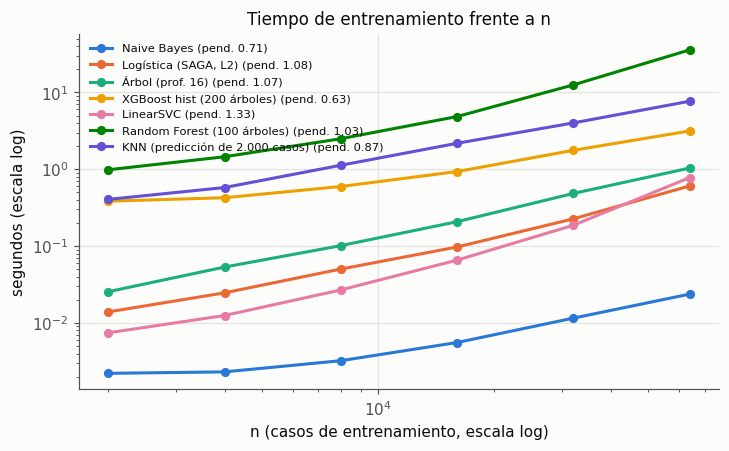

,exponente empírico
modelo,
KNN (predicción de 2.000 casos),0.87
LinearSVC,1.33
"Logística (SAGA, L2)",1.08
Naive Bayes,0.71
Random Forest (100 árboles),1.03
XGBoost hist (200 árboles),0.63
Árbol (prof. 16),1.07


In [3]:
ns = [2000, 4000, 8000, 16000, 32000, 64000]
specs = {
    'Naive Bayes': lambda: BernoulliNB(),
    'Logística (SAGA, L2)': lambda: LogisticRegression(C=0.1, solver='saga', max_iter=300, tol=1e-3),
    'Árbol (prof. 16)': lambda: DecisionTreeClassifier(max_depth=16, min_samples_leaf=10, random_state=0),
    'Random Forest (100 árboles)': lambda: RandomForestClassifier(100, max_depth=20, max_features=0.1, n_jobs=1, random_state=0),
    'XGBoost hist (200 árboles)': lambda: XGBClassifier(n_estimators=200, max_depth=6, tree_method='hist', n_jobs=1, verbosity=0),
    'LinearSVC': lambda: LinearSVC(C=0.1, dual=True, max_iter=3000, tol=1e-3),
}
# Para medir tiempos se usan las 3 clases frecuentes: con n = 2.000 no aparece ningún fallecimiento
# y XGBoost exige que estén todas las clases.
keep3 = yall > 0
X3, y3 = Xall[keep3], yall[keep3] - 1
def run_scaling():
    with threadpool_limits(1):
        out = X.scaling_curves(X3, y3, ns, {k: v for k, v in specs.items() if 'Random' not in k}, repeats=2)
        rf = X.scaling_curves(X3[:max(ns)].toarray(), y3, ns, {k: v for k, v in specs.items() if 'Random' in k}, repeats=1)
        knn_rows = []
        for n in ns:
            knn = KNeighborsClassifier(31, algorithm='brute', n_jobs=1).fit(X3[:n], y3[:n])
            t, sd, mem, _ = X.timed(lambda: knn.predict(Xte[:2000]), 2)
            knn_rows.append({'modelo': 'KNN (predicción de 2.000 casos)', 'n': n, 'fit_s': t, 'fit_sd': sd, 'mem_mb': mem})
    return pd.concat([out, rf, pd.DataFrame(knn_rows)], ignore_index=True)
scal = cache.cached('complexity_scaling', run_scaling)
expo = scal.groupby('modelo').apply(lambda d: X.scaling_exponent(d.n, d.fit_s)).rename('exponente empírico')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, (m, d) in enumerate(scal.groupby('modelo', sort=False)):
    ax.plot(d.n, d.fit_s, marker='o', ms=5, color=P.SERIES[i], label=f'{m} (pend. {expo[m]:.2f})')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('n (casos de entrenamiento, escala log)'); ax.set_ylabel('segundos (escala log)')
ax.set_title('Tiempo de entrenamiento frente a n')
ax.legend(fontsize=7.5, loc='upper left')
P.save(fig, 'e3_comp_escalamiento'); plt.show()
expo.round(2).to_frame()

**Interpretación.** La teoría predice pendiente ≈ 1 para todos estos modelos (lineales en n, salvo
el factor log n de los árboles). Lo medido:

- **Logística (1,08), árbol (1,07) y Random Forest (1,03):** coinciden con la teoría; el factor
  log n del ordenamiento apenas se nota en este rango.
- **KNN (0,87):** la predicción por fuerza bruta es lineal en n por consulta; la pendiente algo menor
  que 1 se debe a costos fijos por consulta que pesan más con n pequeño.
- **LinearSVC (1,33):** algo superlineal: con más datos el solver dual necesita más iteraciones para
  converger (el costo por época es lineal, pero el número de épocas crece).
- **Naive Bayes (0,71) y XGBoost hist (0,63):** sublineales en este rango porque dominan costos fijos
  (crear los histogramas y los árboles en XGBoost, la validación de entrada en Naive Bayes); con n
  mucho mayor la pendiente tendería a 1.

En conjunto, ningún modelo de los usados muestra el comportamiento cuadrático que impediría la
corrida; el cuadrático es el SVM con núcleo (sección 8.7).

## 8.3 KNN: fuerza bruta, árboles de búsqueda y vecinos aproximados (FAISS)

KD-Tree y Ball Tree solo aceleran en dimensión baja; con 210 columnas binarias degeneran a
fuerza bruta. Para compararlos de forma justa se proyecta a 10 componentes con SVD truncada.
FAISS `IndexIVFFlat` agrupa los puntos en `nlist` celdas (k-means) y busca solo en las `nprobe`
celdas más cercanas: es aproximado. Se mide qué fracción de los 31 vecinos exactos recupera.

In [4]:
def run_knn():
    with threadpool_limits(1):
        return X.knn_benchmark(Xall[:30000], yall[:30000], Xte[:5000], yte[:5000], k=31, dims=10)
knn = cache.cached('complexity_knn', run_knn)
knn.round(4)

,método,fit_s,predict_s,mem_mb,balanced_accuracy,recall_vecinos
0,"fuerza bruta (one-hot, p=293)",0.0057,8.9943,2.4065,0.3707,NaN
1,"fuerza bruta (SVD, p=10)",0.0034,0.8334,1.1273,0.3530,NaN
2,"KD-Tree (SVD, p=10)",0.0559,0.5414,2.9394,0.3536,NaN
3,"Ball Tree (SVD, p=10)",0.0368,1.1502,2.8613,0.3533,NaN
4,"FAISS IVF (nlist=64, nprobe=1)",0.0372,0.0574,0.0042,0.3535,0.9697
5,"FAISS IVF (nlist=64, nprobe=8)",0.0112,0.1950,0.0005,0.3534,0.9973


**Interpretación.** Con las 293 columnas one-hot, la fuerza bruta tarda 9,0 s en predecir 5.000 casos.
Proyectando a 10 dimensiones baja a 0,83 s. En dimensión baja, KD-Tree (0,54 s) ya mejora a la fuerza
bruta y Ball Tree (1,15 s) no, porque con 30.000 puntos y p = 10 el árbol todavía poda poco. FAISS IVF
es el más rápido: 0,06 s con `nprobe = 1` (recupera el 97 % de los 31 vecinos exactos) y 0,20 s con
`nprobe = 8` (99,7 %). Es entre 4 y 14 veces más rápido que la fuerza bruta en el mismo espacio, y 46
veces más rápido que la fuerza bruta en el one-hot, **sin pérdida de balanced accuracy** (0,353 frente
a 0,353). El compromiso exactitud-velocidad de la aproximación aquí es casi gratis: un 3 % de vecinos
distintos no cambia el voto. Lo que sí cuesta es la proyección SVD (0,371 → 0,353): con 10 componentes
se pierde información de las categorías. Por eso la corrida usó fuerza bruta en el one-hot. FAISS sería
la opción para predecir los 127.391 casos de la prueba con KNN.

## 8.4 Ridge y Lasso: solvers

Ridge con Cholesky resuelve un sistema p × p (O(n·p² + p³)); SAGA y los gradientes conjugados tienen
costo por época lineal en n y p. (En scikit-learn 1.3, SAGA no ajusta intercepto con matrices
dispersas, así que se le pasa la matriz densa; los gradientes conjugados sí usan la dispersa.)
Para Lasso se compara el descenso por coordenadas con un gradiente estocástico con penalización
L1 (la familia de SAGA). Datos: objetivo de regresión, 20.000 casos de desarrollo.

In [5]:
rs, rdev, rtest = D.regression_sets()
enc_r = M.make_encoder().fit(rdev[D.FEATURES].iloc[:20000])
Ar, Br = enc_r.transform(rdev[D.FEATURES].iloc[:20000]), enc_r.transform(rtest[D.FEATURES])
lin = cache.cached('complexity_linear', lambda: X.linear_solvers(Ar, rdev.y_reg.to_numpy()[:20000], Br, rtest.y_reg.to_numpy()))
lin.round(4)

,método,fit_s,fit_sd,predict_s,mem_mb,rmse
0,"Ridge (cholesky, denso)",0.0416,0.0048,0.0068,17.4164,1.2100
1,Ridge (sparse_cg),0.0208,0.0054,0.0005,3.1484,1.2100
2,"Ridge (SAGA, denso)",0.6494,0.0285,0.0074,17.4156,1.2100
3,Lasso (coordinate descent),0.0862,0.0121,0.0005,2.1408,1.1882
4,Lasso (SAGA vía SGD L1),0.0439,0.0020,0.0008,0.3006,1.1878


**Interpretación.** Con p = 210 la teoría se invierte: Cholesky (O(n·p² + p³)) es muy barato porque
p³ ≈ 9·10⁶ es poco, y SAGA (0,65 s) es 15 veces más lento que Cholesky (0,04 s): necesita varias pasadas
por los datos para converger y se le debe pasar la matriz densa. El ganador es el gradiente conjugado
sobre la matriz **dispersa** (0,02 s y 3,1 MB frente a 17,4 MB), porque solo recorre los valores no nulos
(9 por fila). Los tres llegan al mismo RMSE (1,210). SAGA solo compensa cuando p es tan grande que el
p³ de Cholesky es prohibitivo o los datos no caben en memoria. En Lasso, el gradiente estocástico con
L1 es 2 veces más rápido que el descenso por coordenadas y da el mismo RMSE (1,188).

## 8.5 Naive Bayes: aprendizaje incremental con `partial_fit`

Se entrena con **todo** el desarrollo (269.516 casos) de dos maneras: cargando la matriz completa o
leyendo bloques de 20.000 casos con `partial_fit`. El segundo modo nunca necesita tener todo en
memoria; es la vía para datos que no caben.

In [6]:
nb = cache.cached('complexity_nb', lambda: X.naive_bayes_online(Xall, yall, Xte, yte))
nb.round(4)

,método,fit_s,mem_mb,balanced_accuracy
0,BernoulliNB.fit (todo en memoria),0.0936,50.6971,0.3918
1,"BernoulliNB.partial_fit (bloques de 20,000)",0.0838,4.9196,0.3918


**Interpretación.** `partial_fit` por bloques de 20.000 casos da exactamente el mismo modelo
(balanced accuracy 0,3918 en ambos: Naive Bayes solo suma conteos por clase) con la décima parte de memoria
pico (4,9 MB frente a 50,7 MB) y el mismo tiempo. Con todo el desarrollo (269.516 casos) la memoria no
es un problema, pero el método escala a archivos de cualquier tamaño leyéndolos por partes.

## 8.6 XGBoost: método exacto, histogramas, early stopping y GPU

100.000 casos de entrenamiento, 20.000 de validación (para early stopping) y la muestra de prueba.
`hist` discretiza cada variable en ≤ 256 intervalos y busca divisiones sobre los histogramas en vez
de ordenar todos los valores. Early stopping detiene el boosting cuando el log-loss de un conjunto de
validación independiente deja de mejorar 20 rondas seguidas (máximo 1.000 árboles); se compara con
1.000 árboles fijos.

In [7]:
def run_xgb():
    return X.xgboost_methods(Xall[:100000], yall[:100000], Xall[100000:120000], yall[100000:120000], Xte, yte, gpu=True)
xgbt = cache.cached('complexity_xgb', run_xgb)
xgbt.round(4)

,método,fit_s,fit_sd,predict_s,mem_mb,arboles,balanced_accuracy,log_loss_prueba
0,"exact (CPU, 12 hilos), 400 árboles",17.1777,0.1706,0.1387,4.1470,400,0.4009,0.9286
1,"hist (CPU, 12 hilos), 400 árboles",4.4237,0.0418,0.1367,4.1131,400,0.3995,0.9279
2,"hist (CPU), 1.000 árboles",11.2580,0.0075,0.4084,9.8747,1000,0.3963,0.9341
3,"hist + early stopping (CPU), hasta 1.000",125.6318,0.0000,0.3443,8.2164,802,0.3985,0.9306
4,"hist (GPU, cuda), 400 árboles",5.1332,0.1558,0.0500,4.0998,400,0.4024,0.9268


**Interpretación.**

- **`hist` frente a exacto:** 3,9 veces más rápido (4,4 s frente a 17,2 s con 400 árboles) con el mismo
  desempeño (balanced accuracy 0,400 frente a 0,401; log-loss 0,928 frente a 0,929). Con variables
  binarias, cada columna tiene solo 2 valores, así que el histograma no pierde nada.
- **Early stopping:** se detuvo en 802 árboles (de 1.000) y obtuvo un log-loss de prueba de 0,931, mejor
  que con 1.000 árboles fijos (0,934): evita el leve sobreajuste de las últimas rondas. Pero en tiempo
  costó 126 s frente a 11 s, porque en esta versión de XGBoost evaluar el conjunto de validación en cada
  ronda es caro. Además, el óptimo está en torno a 400–800 árboles con learning rate 0,1, así que aquí la
  parada temprana mejora poco: tiene sentido con presupuestos de árboles mucho mayores.
- **GPU (RTX 3050):** 5,1 s frente a 4,4 s en CPU con 12 hilos (aceleración de 0,86, es decir, más
  lenta) y el mismo desempeño. Con 100.000 filas y 210 columnas binarias, el costo de copiar los datos a la
  GPU y lanzar los núcleos no se amortiza; la GPU convendría con millones de filas o árboles más
  profundos. Por eso la corrida principal usó CPU.

## 8.7 SVM: núcleo RBF frente a LinearSVC y SGD

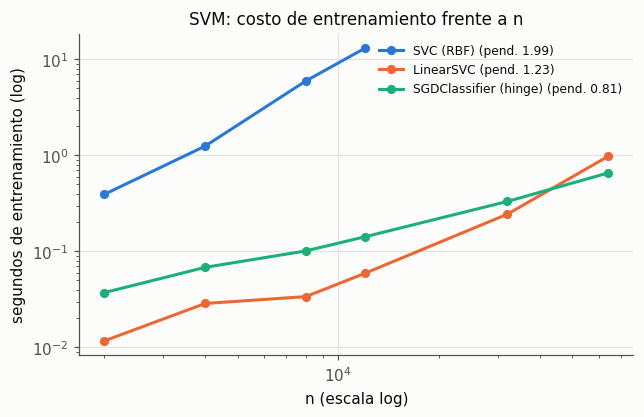

,método,n,fit_s,predict_s,mem_mb,balanced_accuracy
0,SVC (RBF),2000,0.3927,0.3327,1.4498,0.3683
1,LinearSVC,2000,0.0117,0.0010,0.4376,0.3682
2,SGDClassifier (hinge),2000,0.0372,0.0007,0.2231,0.3361
3,SVC (RBF),4000,1.2498,0.7027,2.8746,0.3799
4,LinearSVC,4000,0.0286,0.0011,0.8638,0.3680
5,SGDClassifier (hinge),4000,0.0681,0.0010,0.3796,0.3638
6,SVC (RBF),8000,5.9673,1.2927,5.7432,0.3893
7,LinearSVC,8000,0.0338,0.0006,1.7221,0.3840
8,SGDClassifier (hinge),8000,0.1011,0.0005,0.7364,0.3745
9,SVC (RBF),12000,13.0699,1.8151,8.6121,0.3896


In [8]:
def run_svm():
    with threadpool_limits(1):
        return X.svm_methods(Xall, yall, Xte[:3000], yte[:3000], [2000, 4000, 8000, 12000, 32000, 64000])
svm = cache.cached('complexity_svm', run_svm)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, (m, d) in enumerate(svm.groupby('método', sort=False)):
    ax.plot(d.n, d.fit_s, marker='o', ms=5, color=P.SERIES[i], label=f'{m} (pend. {X.scaling_exponent(d.n, d.fit_s):.2f})')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('n (escala log)'); ax.set_ylabel('segundos de entrenamiento (log)')
ax.set_title('SVM: costo de entrenamiento frente a n'); ax.legend(fontsize=8)
P.save(fig, 'e3_comp_svm'); plt.show()
svm.round(4)

**Interpretación.** El SVM con núcleo RBF tiene un exponente empírico cercano a 2 (pasar de 2.000 a
12.000 casos multiplica por 33 el tiempo: de 0,39 s a 13,1 s), coherente con su complejidad O(n²·p) a
O(n³). Extrapolando, con 24.000 casos (un entrenamiento externo) tardaría cerca de 1 minuto por ajuste, y
cada combinación necesita 245 ajustes; con el desarrollo completo (269.516) serían horas por ajuste.
`LinearSVC` y SGD crecen casi linealmente (LinearSVC: 0,06 s con 12.000 y 0,98 s con 64.000) y su
predicción es instantánea. En desempeño, el RBF es apenas mejor con el mismo n (0,390 frente a 0,389 con
12.000), y LinearSVC con 64.000 casos (0,400) supera al RBF con el máximo de 12.000 que es viable
entrenar: más datos con un modelo lineal valen más que el núcleo con pocos datos.

## 8.8 Paralelización con joblib

Tarea de referencia: ajustar una logística (SAGA) sobre 20.000 casos, 12 veces. Se compara la
ejecución en serie con 6 procesos (`loky`) y 6 hilos (`threading`). Los procesos evitan el GIL
de Python; los hilos solo escalan cuando el trabajo pesado libera el GIL (código en C/Cython).

La corrida principal (`nested.run_all`) usa `loky` con 11 procesos, un hilo de BLAS/OpenMP por
proceso (`threadpool_limits(1)`) para no sobresuscribir los 12 hilos, y reparte celdas
(combinación × pliegue externo) ordenadas de la más costosa a la más barata para equilibrar la
carga. Dask o Ray no se usaron: todo corre en una sola máquina y joblib ya satura sus núcleos;
serían útiles para repartir las 700 celdas entre varias máquinas.

In [9]:
Xj, yj = Xall[:20000], yall[:20000]
def work(i):
    with threadpool_limits(1):
        LogisticRegression(C=0.1, solver='saga', max_iter=100, tol=1e-3, random_state=i).fit(Xj, yj)
    return i
jb = cache.cached('complexity_joblib', lambda: X.joblib_backends(work, n_tasks=12, n_jobs=6))
jb.round(2)

,backend,n_jobs,segundos,aceleración
0,serie (1 proceso),1,9.17,1.00
1,loky,6,4.16,2.20
2,threading,6,2.20,4.18


**Interpretación.** Con 6 procesos `loky` acelera 2,2 veces y `threading` 4,2 veces. Que los hilos ganen
a los procesos se explica porque el solver SAGA está escrito en Cython y libera el GIL, así que los hilos
trabajan en paralelo de verdad sin el costo de arrancar procesos y copiarles los datos (que en `loky` se
paga en cada lote de tareas cortas). La aceleración queda lejos de 6 por el ancho de banda de memoria
compartido. Para la corrida principal se usó `loky` igualmente: allí cada tarea dura minutos (el costo
de arranque es despreciable) y mezcla código Python (Optuna, DEAP, imblearn) que no libera el GIL.

## 8.9 Perfilamiento: dónde se va el tiempo de una búsqueda

Se perfila con `cProfile` una búsqueda corta (4 configuraciones) de SVM con ADASYN, la combinación
que más sorprendió en las pruebas: el modelo es rápido, pero la búsqueda no. Se compara el
evaluador **sin** caché (reajusta el pipeline completo, incluido ADASYN, en cada configuración) y
**con** caché (codificación y remuestreo una vez por pliegue interno).

In [10]:
Xs, ys, gs, ss = N.task_data('clf')
tr, te = N.outer_folds('clf')[0]
folds = N.inner_folds('clf', tr, 0)
Xtr, ytr = Xs.iloc[tr].reset_index(drop=True), ys[tr]

class NoCacheEvaluator(S.Evaluator):
    """Evaluador sin caché: ajusta el pipeline completo en cada configuración."""
    def __call__(self, params):
        start = time.perf_counter(); scores = []
        for a, b in self.folds:
            pipe = S.refit(self.task, self.name, params, self.balance, self.X.iloc[a], self.y[a], self.seed)
            scores.append(S.score_predictions(self.task, self.y[b], pipe, self.X.iloc[b]))
        self.history.append({'eval': len(self.history) + 1, 'params': params, 'score': float(np.mean(scores)),
                             'seconds': time.perf_counter() - start, 'elapsed': time.perf_counter() - self.t0})
        return float(np.mean(scores))

def run_profile():
    out = {}
    for label, cls in [('sin caché', NoCacheEvaluator), ('con caché', S.Evaluator)]:
        ev = cls('clf', 'svm', 'adasyn', Xtr, ytr, folds, C.SEED, 4)
        t0 = time.perf_counter()
        prof = X.profile(lambda: S.run_search('random', ev, 'clf', 'svm', 7), top=12)
        out[label] = {'seconds': time.perf_counter() - t0, 'best': ev.best()[1], 'profile': prof}
    return out
prof = cache.cached('complexity_profile', run_profile)
print({k: (round(v['seconds'], 1), round(v['best'], 4)) for k, v in prof.items()})
prof['sin caché']['profile'].round(3)

{'sin caché': (127.1, 0.3785), 'con caché': (42.1, 0.3785)}


,función,llamadas,tiempo_propio_s,tiempo_acumulado_s
583,<lambda> (1287869174.py:22),1,0.000,127.111
172,run_search (search.py:255),1,0.000,127.111
171,random_search (search.py:148),1,0.000,127.110
0,__call__ (1287869174.py:8),4,0.007,127.110
173,refit (search.py:263),12,0.000,126.847
328,wrapper (base.py:1134),84,0.003,126.847
152,fit (pipeline.py:280),12,0.000,126.843
151,_fit (pipeline.py:228),12,0.001,114.163
414,__call__ (memory.py:352),24,0.000,114.161
157,_fit_resample_one (pipeline.py:1055),12,0.002,111.957


In [11]:
prof['con caché']['profile'].round(3)

,función,llamadas,tiempo_propio_s,tiempo_acumulado_s
515,<lambda> (1287869174.py:22),1,0.000,42.057
150,run_search (search.py:255),1,0.000,42.057
149,random_search (search.py:148),1,0.000,42.057
146,__call__ (search.py:114),4,0.000,42.057
144,_prepare (search.py:88),1,0.003,28.642
509,fit_resample (models.py:127),3,0.003,28.010
505,kneighbors (_base.py:730),18,0.000,27.969
492,compute (_dispatcher.py:165),18,0.000,27.966
520,<built-in method compute> (~:0),18,27.962,27.966
286,wrapper (base.py:1134),27,0.000,13.893


**Interpretación.** El perfil muestra el cuello de botella real, que no era el modelo. Sin caché, la
búsqueda de 4 configuraciones tardó 127 s y el 88 % del tiempo (112 s) se fue en `fit_resample` de
ADASYN, concretamente en la búsqueda de vecinos (`kneighbors`), que se repetía en cada configuración y en
cada pliegue. LinearSVC en sí costaba ~13 s. Con la caché (codificación y remuestreo una vez por pliegue
interno) la misma búsqueda tardó 42 s, **3 veces menos con exactamente el mismo resultado** (0,3785 en
ambos casos), y el tiempo restante se reparte entre ADASYN (28 s, una vez por pliegue) y el modelo (13
s). Con 16 configuraciones la ganancia es mayor. Es un ejemplo de lo que pide la guía: perfilar antes de
optimizar; la intuición habría apuntado al modelo y no al remuestreo.

## 8.10 Resumen: modelo estándar frente a optimizado

In [12]:
def row(modelo, est, opt, comp_est, comp_opt, fit_e, fit_o, pred_e, pred_o, mem_e, mem_o, perf_e, perf_o, metric):
    return {'Modelo': modelo, 'Estándar': est, 'Optimizado': opt, 'Complejidad estándar': comp_est,
            'Complejidad optimizada': comp_opt, 'Entrenamiento estándar (s)': fit_e, 'Entrenamiento optimizado (s)': fit_o,
            'Inferencia estándar (s)': pred_e, 'Inferencia optimizada (s)': pred_o,
            'Memoria estándar (MB)': mem_e, 'Memoria optimizada (MB)': mem_o,
            f'Desempeño estándar': perf_e, f'Desempeño optimizado': perf_o, 'Métrica': metric}
k = knn.set_index('método'); xg = xgbt.set_index('método'); l = lin.set_index('método'); n_ = nb.set_index('método')
sv = svm[svm.n == svm[svm['método'] == 'SVC (RBF)'].n.max()].set_index('método')
ri, ro = 'Ridge (cholesky, denso)', 'Ridge (sparse_cg)'
xe, xh = 'exact (CPU, 12 hilos), 400 árboles', 'hist (CPU, 12 hilos), 400 árboles'
kb = [i for i in k.index if i.startswith('fuerza bruta (SVD')][0]; kf = [i for i in k.index if 'nprobe=8' in i][0]
summary = pd.DataFrame([
    row('KNN', kb, kf, 'O(n·p)/consulta', 'O((n/nlist)·nprobe·p)', k.loc[kb, 'fit_s'], k.loc[kf, 'fit_s'],
        k.loc[kb, 'predict_s'], k.loc[kf, 'predict_s'], k.loc[kb, 'mem_mb'], k.loc[kf, 'mem_mb'],
        k.loc[kb, 'balanced_accuracy'], k.loc[kf, 'balanced_accuracy'], 'balanced acc.'),
    row('Ridge', ri, ro, 'O(n·p² + p³)', 'O(nnz·iter), disperso', l.loc[ri, 'fit_s'], l.loc[ro, 'fit_s'],
        l.loc[ri, 'predict_s'], l.loc[ro, 'predict_s'], l.loc[ri, 'mem_mb'], l.loc[ro, 'mem_mb'],
        l.loc[ri, 'rmse'], l.loc[ro, 'rmse'], 'RMSE'),
    row('Naive Bayes', n_.index[0], n_.index[1], 'O(n·p), todo en memoria', 'O(n·p), por bloques',
        n_.iloc[0].fit_s, n_.iloc[1].fit_s, np.nan, np.nan, n_.iloc[0].mem_mb, n_.iloc[1].mem_mb,
        n_.iloc[0].balanced_accuracy, n_.iloc[1].balanced_accuracy, 'balanced acc.'),
    row('XGBoost', xe, xh, 'O(T·p·n log n)', 'O(T·p·n) + O(T·p·bins)', xg.loc[xe, 'fit_s'], xg.loc[xh, 'fit_s'],
        xg.loc[xe, 'predict_s'], xg.loc[xh, 'predict_s'], xg.loc[xe, 'mem_mb'], xg.loc[xh, 'mem_mb'],
        xg.loc[xe, 'balanced_accuracy'], xg.loc[xh, 'balanced_accuracy'], 'balanced acc.'),
    row('SVM', 'SVC (RBF)', 'LinearSVC', 'O(n²·p) a O(n³)', 'O(n·p) por época',
        sv.loc['SVC (RBF)', 'fit_s'], sv.loc['LinearSVC', 'fit_s'], sv.loc['SVC (RBF)', 'predict_s'], sv.loc['LinearSVC', 'predict_s'],
        sv.loc['SVC (RBF)', 'mem_mb'], sv.loc['LinearSVC', 'mem_mb'], sv.loc['SVC (RBF)', 'balanced_accuracy'],
        sv.loc['LinearSVC', 'balanced_accuracy'], 'balanced acc.'),
])
summary.round(4).set_index('Modelo')

,Estándar,Optimizado,Complejidad estándar,Complejidad optimizada,Entrenamiento estándar (s),Entrenamiento optimizado (s),Inferencia estándar (s),Inferencia optimizada (s),Memoria estándar (MB),Memoria optimizada (MB),Desempeño estándar,Desempeño optimizado,Métrica
Modelo,,,,,,,,,,,,,
KNN,"fuerza bruta (SVD, p=10)","FAISS IVF (nlist=64, nprobe=8)",O(n·p)/consulta,O((n/nlist)·nprobe·p),0.0034,0.0112,0.8334,0.1950,1.1273,0.0005,0.3530,0.3534,balanced acc.
Ridge,"Ridge (cholesky, denso)",Ridge (sparse_cg),O(n·p² + p³),"O(nnz·iter), disperso",0.0416,0.0208,0.0068,0.0005,17.4164,3.1484,1.2100,1.2100,RMSE
Naive Bayes,BernoulliNB.fit (todo en memoria),"BernoulliNB.partial_fit (bloques de 20,000)","O(n·p), todo en memoria","O(n·p), por bloques",0.0936,0.0838,NaN,NaN,50.6971,4.9196,0.3918,0.3918,balanced acc.
XGBoost,"exact (CPU, 12 hilos), 400 árboles","hist (CPU, 12 hilos), 400 árboles",O(T·p·n log n),O(T·p·n) + O(T·p·bins),17.1777,4.4237,0.1387,0.1367,4.1470,4.1131,0.4009,0.3995,balanced acc.
SVM,SVC (RBF),LinearSVC,O(n²·p) a O(n³),O(n·p) por época,13.0699,0.0590,1.8151,0.0006,8.6121,2.5513,0.3896,0.3889,balanced acc.


**Interpretación.** Resumen de las optimizaciones con su efecto medido:

| Modelo | Cambio | Efecto en tiempo | Efecto en memoria | Efecto en desempeño |
|---|---|---|---|---|
| KNN | FAISS IVF en lugar de fuerza bruta (mismo espacio de 10 dimensiones) | predicción 4 veces más rápida | despreciable | ninguno (0,353) |
| Ridge | gradiente conjugado sobre la matriz dispersa en lugar de Cholesky denso | 2 veces más rápido | 5,5 veces menos | ninguno (RMSE 1,210) |
| Naive Bayes | `partial_fit` por bloques | igual | 10 veces menos | ninguno |
| XGBoost | `hist` en lugar de exacto | 3,9 veces más rápido | igual | ninguno |
| SVM | LinearSVC en lugar de SVC con núcleo RBF (12.000 casos) | 220 veces más rápido al entrenar y 3.000 al predecir | 3,4 veces menos | ninguno (0,389 frente a 0,390) |
| Búsqueda | caché de codificación y remuestreo por pliegue | 3 veces más rápida | algo más (guarda 3 matrices) | ninguno |

En todos los casos el desempeño se mantuvo y el costo bajó; el análisis de complejidad anticipó cuáles
cambios iban a importar (SVM, KNN) y el perfilamiento encontró el que la teoría no mostraba (el remuestreo
repetido). La GPU y el early stopping, en cambio, no ayudaron con el tamaño de este problema.